# Spotify Songs' Genre Segmentation and Music Recommendation System
B.Tech CSE Minor Project

This notebook runs the whole project in order: dataset inspection, preprocessing, visualization, correlation, K-Means clustering, cluster analysis and the recommender. All numbers come from the uploaded Spotify CSV.

**Run order:** use *Kernel > Restart & Run All*. The first cell moves to the project folder.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")                      # go to the Spotify_Minor_Project folder
sys.path.append("backend")             # so we can import recommender.py
import pandas as pd
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
print("Working folder:", os.getcwd())


Working folder: /mnt/user-data/outputs/Spotify_Minor_Project


## 1. Dataset inspection
**What:** look at the raw CSV: size, columns, data types, missing values, duplicates.
**Why:** we must understand the data before cleaning or modelling it.

Key facts: 32,833 rows and 23 columns. Only `track_name`, `track_artist` and `track_album_name` have missing values (5 each). No row is fully duplicated, but 4,477 `track_id` values repeat because one song can be in several playlists.

In [2]:
# Part 1 - Dataset Inspection
import pandas as pd

df = pd.read_csv("dataset/spotify_dataset.csv")

print("1. Rows    :", df.shape[0])
print("2. Columns :", df.shape[1])
print("\n3. Column names:\n", list(df.columns))
print("\n4. Data types:\n", df.dtypes)

print("\n5. Missing values (only columns that have any):")
missing = df.isnull().sum()
print(missing[missing > 0])

print("\n6. Duplicate rows (full row identical):", df.duplicated().sum())
print("   Duplicate track_id values            :", df["track_id"].duplicated().sum())

numerical = df.select_dtypes(include="number").columns.tolist()
categorical = df.select_dtypes(exclude="number").columns.tolist()
print("\n7. Numerical columns  :", numerical)
print("8. Categorical columns:", categorical)

audio_features = ["danceability", "energy", "loudness", "speechiness", "acousticness",
                  "instrumentalness", "liveness", "valence", "tempo"]
print("\n9. Spotify audio features used:", audio_features)
print(df[audio_features].describe().T[["min", "mean", "max"]])

print("\n10. playlist_genre:", df["playlist_genre"].nunique(), "unique values")
print(df["playlist_genre"].value_counts())

print("\n11. playlist_name:", df["playlist_name"].nunique(), "unique values")
print(df["playlist_name"].value_counts().head(5))


1. Rows    : 32833
2. Columns : 23

3. Column names:
 ['track_id', 'track_name', 'track_artist', 'track_popularity', 'track_album_id', 'track_album_name', 'track_album_release_date', 'playlist_name', 'playlist_id', 'playlist_genre', 'playlist_subgenre', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms']

4. Data types:
 track_id                        str
track_name                      str
track_artist                    str
track_popularity              int64
track_album_id                  str
track_album_name                str
track_album_release_date        str
playlist_name                   str
playlist_id                     str
playlist_genre                  str
playlist_subgenre               str
danceability                float64
energy                      float64
key                           int64
loudness                    float64
mode                          int64
sp

## 2. Data preprocessing
**What:** drop the 5 rows with no song name, remove duplicate songs (by `track_id`, then by name + artist), keep only the useful columns, and save `spotify_cleaned.csv`.
**Why:** missing or repeated rows would distort the plots and clusters and make the recommender repeat songs.

Result: 32,833 rows reduced to **26,229 unique songs** and 16 columns.

In [3]:
# Part 2 - Data Preprocessing
import pandas as pd

RAW_PATH = "dataset/spotify_dataset.csv"
CLEAN_PATH = "dataset/spotify_cleaned.csv"

AUDIO_FEATURES = ["danceability", "energy", "loudness", "speechiness", "acousticness",
                  "instrumentalness", "liveness", "valence", "tempo"]

# Columns we keep (the rest, like album ids and release date, are not needed)
KEEP_COLUMNS = ["track_id", "track_name", "track_artist", "track_popularity",
                "playlist_name", "playlist_genre", "playlist_subgenre"] + AUDIO_FEATURES


def preprocess():
    # 1. Load CSV
    df = pd.read_csv(RAW_PATH)
    print("1. Loaded:", df.shape)

    # 2-3. Check and handle missing values
    print("\n2. Missing values before cleaning:")
    missing = df.isnull().sum()
    print(missing[missing > 0])
    # Only 5 rows have no song name/artist. We cannot recommend a song with no name,
    # so we drop these rows (very few, so no data is really lost).
    df = df.dropna(subset=["track_name", "track_artist"])
    print("3. After dropping rows with missing name/artist:", df.shape)

    # 4-5. Check and remove duplicates
    print("\n4. Duplicate track_id before removing:", df["track_id"].duplicated().sum())
    df = df.drop_duplicates(subset="track_id", keep="first")
    # Same song name + artist can also appear with different track_ids (e.g. album vs single)
    print("   Same track_name + artist (different id):",
          df.duplicated(subset=["track_name", "track_artist"]).sum())
    df = df.drop_duplicates(subset=["track_name", "track_artist"], keep="first")
    print("5. After removing duplicates:", df.shape)

    # 6. Check numerical data
    print("\n6. Numeric check on audio features:")
    print("   Non-numeric columns among features:",
          [c for c in AUDIO_FEATURES if not pd.api.types.is_numeric_dtype(df[c])])
    print("   Missing in audio features:", int(df[AUDIO_FEATURES].isnull().sum().sum()))
    print(df[AUDIO_FEATURES].describe().T[["min", "mean", "max"]])

    # 7-8. Select relevant columns and prepare cleaned dataset
    df = df[KEEP_COLUMNS].reset_index(drop=True)
    print("\n7. Columns kept:", list(df.columns))

    # 9. Save
    df.to_csv(CLEAN_PATH, index=False)
    print("\n9. Saved", CLEAN_PATH, "with shape", df.shape)
    print("\nGenre counts after cleaning:\n", df["playlist_genre"].value_counts())
    return df


if __name__ == "__main__":
    preprocess()


1. Loaded: (32833, 23)

2. Missing values before cleaning:
track_name          5
track_artist        5
track_album_name    5
dtype: int64
3. After dropping rows with missing name/artist: (32828, 23)

4. Duplicate track_id before removing: 4476
   Same track_name + artist (different id): 2123
5. After removing duplicates: (26229, 23)

6. Numeric check on audio features:
   Non-numeric columns among features: []
   Missing in audio features: 0
                        min        mean      max
danceability       0.000000    0.653649    0.983
energy             0.000175    0.696510    1.000
loudness         -46.448000   -6.838346    1.275
speechiness        0.000000    0.108737    0.918
acousticness       0.000000    0.180849    0.994
instrumentalness   0.000000    0.095124    0.994
liveness           0.000000    0.191124    0.996
valence            0.000000    0.506352    0.991
tempo              0.000000  121.003662  239.440

7. Columns kept: ['track_id', 'track_name', 'track_artist', 'tr


9. Saved dataset/spotify_cleaned.csv with shape (26229, 16)

Genre counts after cleaning:
 playlist_genre
rap      5165
pop      4836
edm      4603
r&b      4067
latin    3819
rock     3739
Name: count, dtype: int64


## 3. Data analysis and visualization
**What:** 11 graphs: genre and subgenre counts, distributions of popularity, danceability, energy, loudness, acousticness and valence, energy vs danceability, and genre vs energy / danceability.
**Why:** to see patterns in the data before clustering.

Examples from the results: EDM has the highest median energy (0.838) and R&B the lowest (0.590). Rap (0.733) and latin (0.726) are the most danceable, rock the least (0.521). 2,368 songs have popularity exactly 0.

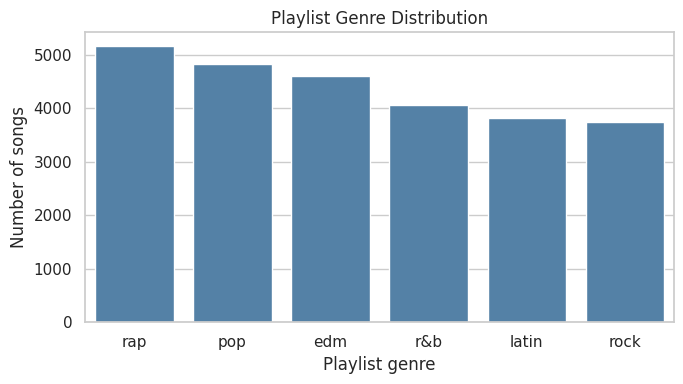

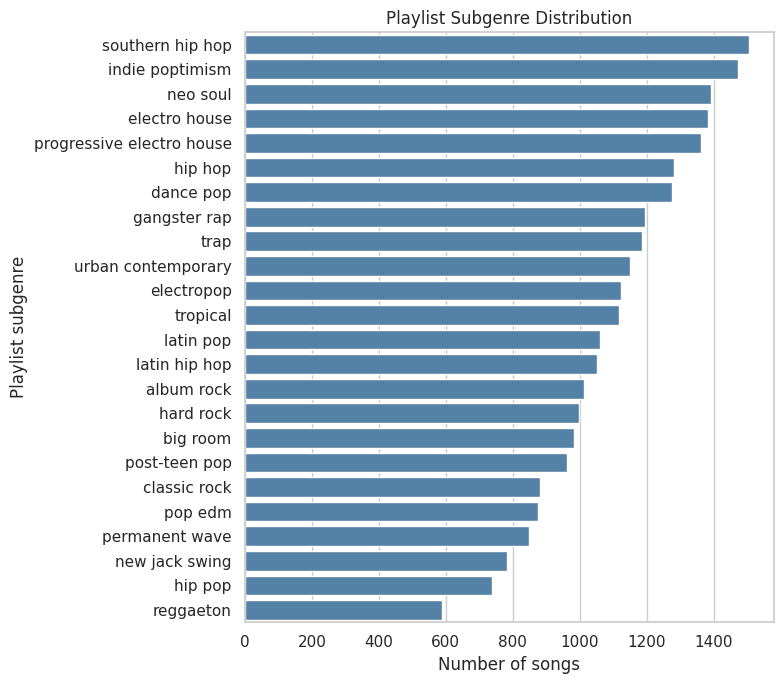

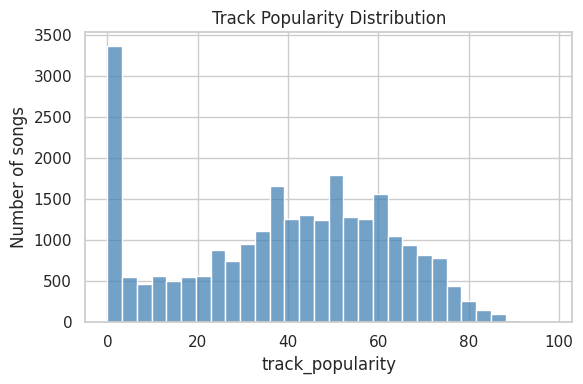

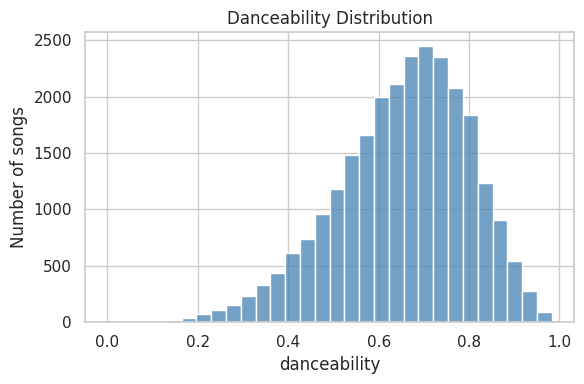

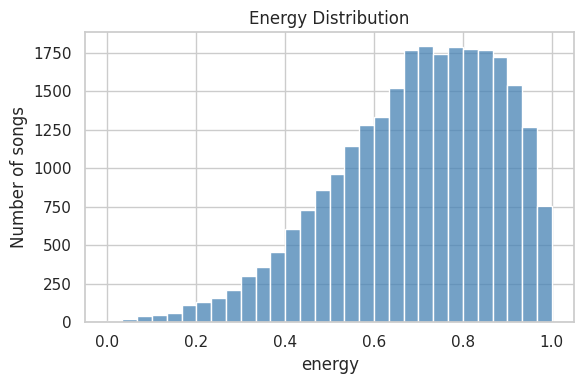

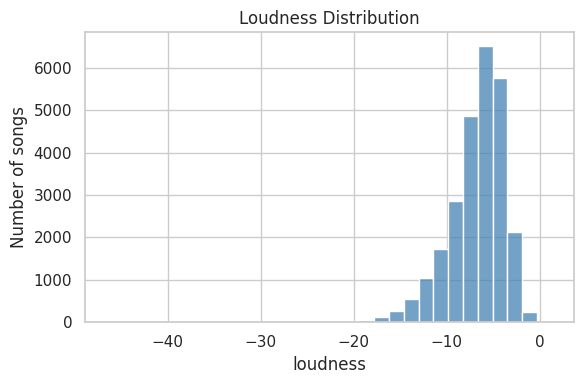

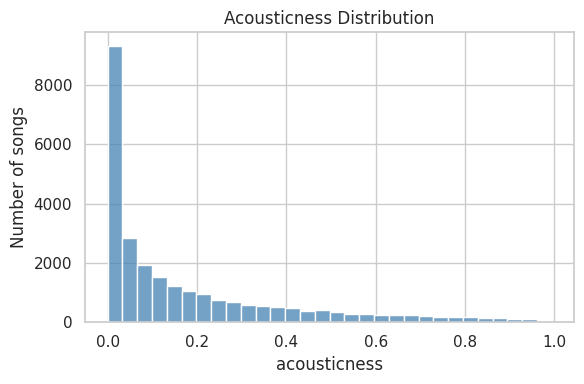

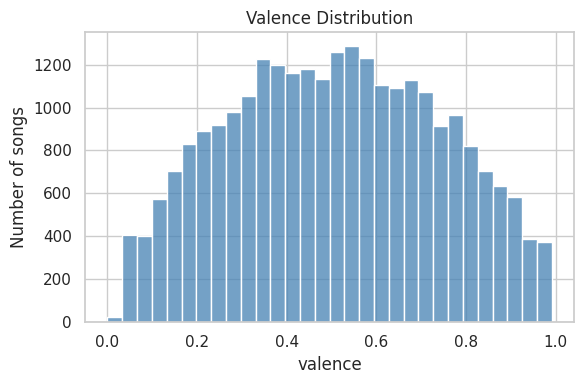

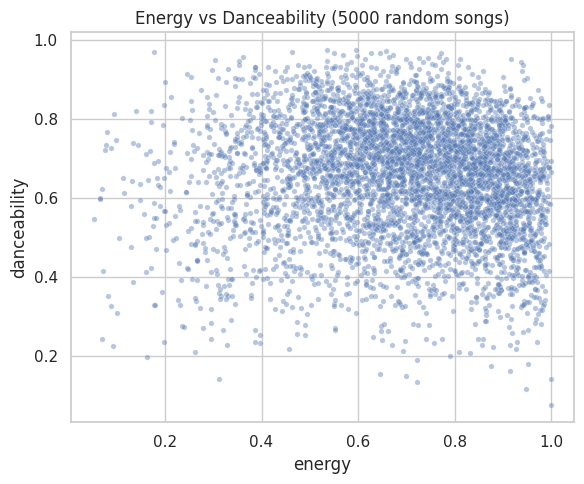

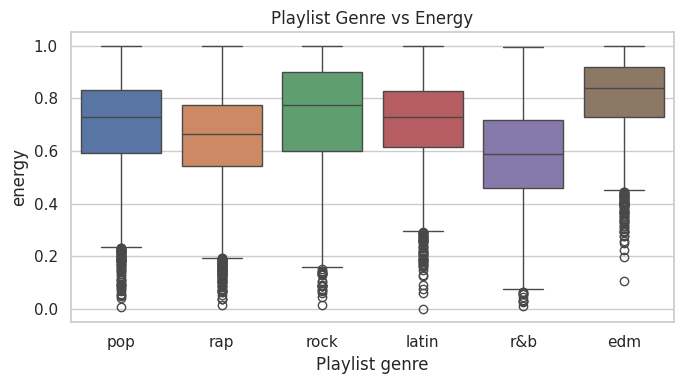

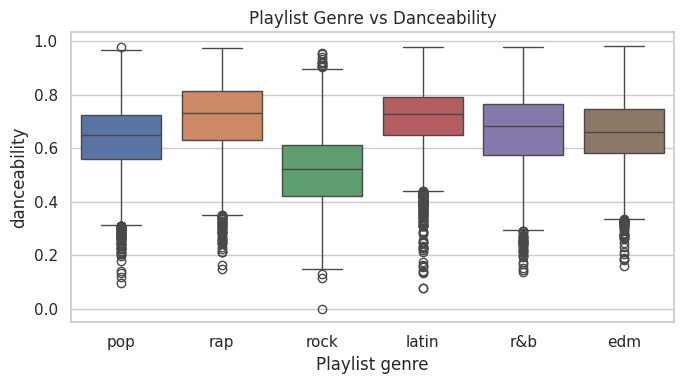

Songs: 26229

Genre counts:
 playlist_genre
rap      5165
pop      4836
edm      4603
r&b      4067
latin    3819
rock     3739
Name: count, dtype: int64

Top 3 / bottom 3 subgenres:
 playlist_subgenre
southern hip hop    1505
indie poptimism     1474
neo soul            1393
new jack swing       784
hip pop              739
reggaeton            588
Name: count, dtype: int64

Mean / median of features:
                    mean  median
track_popularity  39.508  42.000
danceability       0.654   0.670
energy             0.697   0.720
loudness          -6.838  -6.274
acousticness       0.181   0.082
valence            0.506   0.507

Songs with popularity 0: 2368
Songs with acousticness < 0.2: 68.5 %
Songs with loudness > -10: 86.1 %
Energy vs danceability correlation: -0.073

Median energy by genre:
 playlist_genre
r&b      0.590
rap      0.665
pop      0.727
latin    0.728
rock     0.775
edm      0.838
Name: energy, dtype: float64

Median danceability by genre:
 playlist_genre
rock     0

In [4]:
# Part 3 - Data Analysis and Visualization
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("dataset/spotify_cleaned.csv")
OUT = "visualizations/"


def save(name):
    plt.tight_layout()
    plt.savefig(OUT + name, dpi=150)
    plt.show()


# 1. Playlist genre distribution
order = df["playlist_genre"].value_counts().index
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="playlist_genre", order=order, color="steelblue")
plt.title("Playlist Genre Distribution"); plt.xlabel("Playlist genre"); plt.ylabel("Number of songs")
save("01_genre_distribution.png")

# 2. Playlist subgenre distribution
order = df["playlist_subgenre"].value_counts().index
plt.figure(figsize=(8, 7))
sns.countplot(data=df, y="playlist_subgenre", order=order, color="steelblue")
plt.title("Playlist Subgenre Distribution"); plt.xlabel("Number of songs"); plt.ylabel("Playlist subgenre")
save("02_subgenre_distribution.png")

# 3-8. Histograms of single features
hist_plots = [("track_popularity", "03_popularity_distribution.png"),
              ("danceability", "04_danceability_distribution.png"),
              ("energy", "05_energy_distribution.png"),
              ("loudness", "06_loudness_distribution.png"),
              ("acousticness", "07_acousticness_distribution.png"),
              ("valence", "08_valence_distribution.png")]
for col, filename in hist_plots:
    plt.figure(figsize=(6, 4))
    sns.histplot(df[col], bins=30, color="steelblue")
    plt.title(f"{col.replace('_', ' ').title()} Distribution"); plt.xlabel(col); plt.ylabel("Number of songs")
    save(filename)

# 9. Energy vs Danceability (sample of 5000 songs so the plot is not too crowded)
sample = df.sample(5000, random_state=42)
plt.figure(figsize=(6, 5))
sns.scatterplot(data=sample, x="energy", y="danceability", alpha=0.4, s=15)
plt.title("Energy vs Danceability (5000 random songs)")
save("09_energy_vs_danceability.png")

# 10. Genre vs Energy
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="playlist_genre", y="energy", hue="playlist_genre", legend=False)
plt.title("Playlist Genre vs Energy"); plt.xlabel("Playlist genre")
save("10_genre_vs_energy.png")

# 11. Genre vs Danceability
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="playlist_genre", y="danceability", hue="playlist_genre", legend=False)
plt.title("Playlist Genre vs Danceability"); plt.xlabel("Playlist genre")
save("11_genre_vs_danceability.png")

# ---- Numbers used for the observations ----
print("Songs:", len(df))
print("\nGenre counts:\n", df["playlist_genre"].value_counts())
print("\nTop 3 / bottom 3 subgenres:\n", df["playlist_subgenre"].value_counts().iloc[[0, 1, 2, -3, -2, -1]])
print("\nMean / median of features:")
print(df[["track_popularity", "danceability", "energy", "loudness", "acousticness", "valence"]].agg(["mean", "median"]).T.round(3))
print("\nSongs with popularity 0:", (df["track_popularity"] == 0).sum())
print("Songs with acousticness < 0.2:", round((df["acousticness"] < 0.2).mean() * 100, 1), "%")
print("Songs with loudness > -10:", round((df["loudness"] > -10).mean() * 100, 1), "%")
print("Energy vs danceability correlation:", round(df["energy"].corr(df["danceability"]), 3))
print("\nMedian energy by genre:\n", df.groupby("playlist_genre")["energy"].median().sort_values().round(3))
print("\nMedian danceability by genre:\n", df.groupby("playlist_genre")["danceability"].median().sort_values().round(3))
print("\nZero-value check -> tempo==0:", (df["tempo"] == 0).sum(), "| danceability==0:", (df["danceability"] == 0).sum())


## 4. Correlation matrix
**What:** correlation between the 9 audio features (-1 to +1).
**Why:** shows which features move together.

Strongest positive: energy and loudness (0.686). Strongest negative: energy and acousticness (-0.551). Only 2 of 36 pairs are above 0.5 in either direction, so most features are fairly independent.

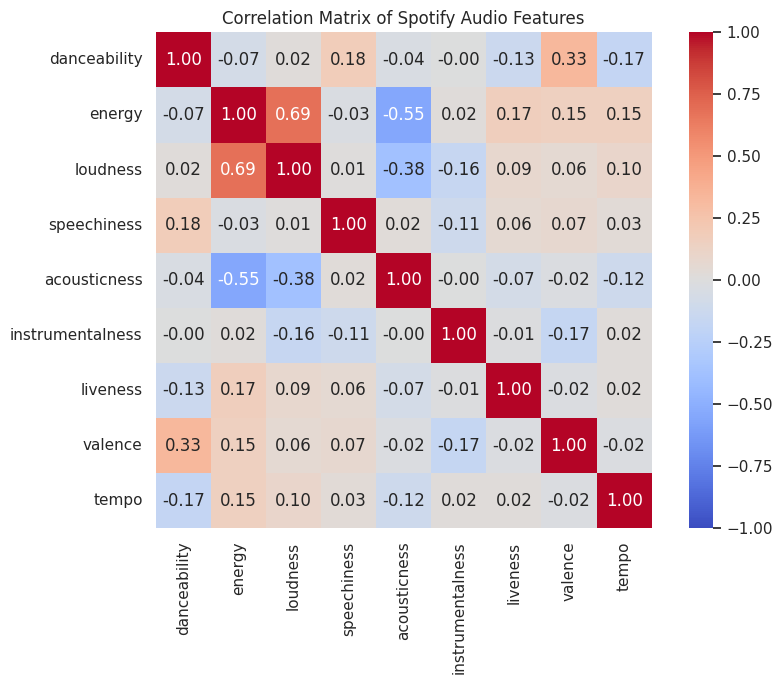

Strongest NEGATIVE pairs:
 energy vs acousticness        -0.551
loudness vs acousticness      -0.377
danceability vs tempo         -0.175
instrumentalness vs valence   -0.171
dtype: float64

Strongest POSITIVE pairs:
 energy vs liveness             0.166
danceability vs speechiness    0.183
danceability vs valence        0.335
energy vs loudness             0.686
dtype: float64

Weakest pairs (closest to 0):
 danceability vs instrumentalness    0.001
acousticness vs instrumentalness    0.004
loudness vs speechiness             0.013
instrumentalness vs liveness        0.013
dtype: float64

Pairs with |corr| >= 0.5: 2 of 36


In [5]:
# Part 4 - Correlation Matrix
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("dataset/spotify_cleaned.csv")

AUDIO_FEATURES = ["danceability", "energy", "loudness", "speechiness", "acousticness",
                  "instrumentalness", "liveness", "valence", "tempo"]

corr = df[AUDIO_FEATURES].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation Matrix of Spotify Audio Features")
plt.tight_layout()
plt.savefig("visualizations/correlation_matrix.png", dpi=150)
plt.show()

# List every pair of features once, then sort by correlation value
pair_list = []
for i in range(len(AUDIO_FEATURES)):
    for j in range(i + 1, len(AUDIO_FEATURES)):
        a, b = AUDIO_FEATURES[i], AUDIO_FEATURES[j]
        pair_list.append((a + " vs " + b, corr.loc[a, b]))
pairs = pd.Series(dict(pair_list)).sort_values()

print("Strongest NEGATIVE pairs:\n", pairs.head(4).round(3))
print("\nStrongest POSITIVE pairs:\n", pairs.tail(4).round(3))
print("\nWeakest pairs (closest to 0):\n", pairs.abs().sort_values().head(4).round(3))
print("\nPairs with |corr| >= 0.5:", int((pairs.abs() >= 0.5).sum()), "of", len(pairs))


## 5. K-Means clustering: choosing K
**What:** scale the 9 features with `StandardScaler`, then run K-Means for K = 2 to 10 and record the Elbow (inertia) and Silhouette scores.
**Why scaling:** tempo and loudness have much bigger numbers than the 0 to 1 features and would dominate the distance.

**Choice: K = 6.** K = 2 has the highest silhouette (0.1939) but is too coarse. Among K = 4 to 10, K = 6 scores best (0.1575) and the elbow curve flattens after it. All silhouette scores are low (0.14 to 0.19), so the clusters overlap.

K= 2  inertia=  199550.7  silhouette=0.1939


K= 3  inertia=  177570.3  silhouette=0.1391


K= 4  inertia=  161042.8  silhouette=0.1519


K= 5  inertia=  146773.8  silhouette=0.1538


K= 6  inertia=  136480.1  silhouette=0.1575


K= 7  inertia=  128946.8  silhouette=0.1441


K= 8  inertia=  122863.6  silhouette=0.1388


K= 9  inertia=  117887.2  silhouette=0.1453


K=10  inertia=  113889.0  silhouette=0.1445


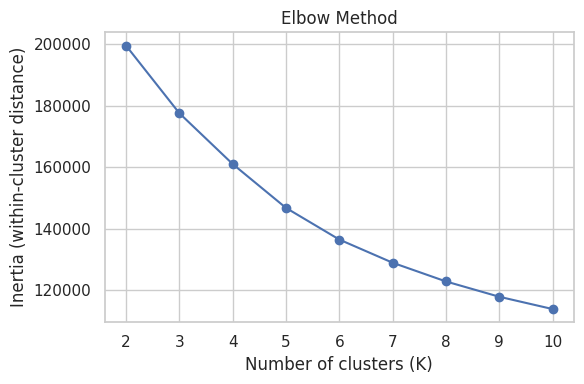

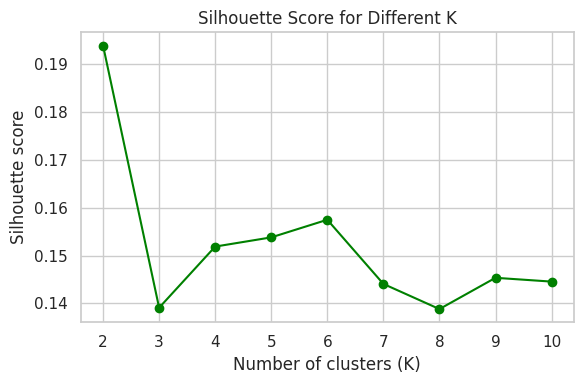

In [6]:
# Part 5a - Find the best K (Elbow + Silhouette)
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv("dataset/spotify_cleaned.csv")
FEATURES = ["danceability", "energy", "loudness", "speechiness", "acousticness",
            "instrumentalness", "liveness", "valence", "tempo"]

# Standardize: every feature gets mean 0 and standard deviation 1
X_scaled = StandardScaler().fit_transform(df[FEATURES])

k_values = list(range(2, 11))
inertia_list, silhouette_list = [], []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    inertia_list.append(km.inertia_)
    # silhouette on 10,000 random songs to keep it fast
    sil = silhouette_score(X_scaled, km.labels_, sample_size=10000, random_state=42)
    silhouette_list.append(sil)
    print(f"K={k:2d}  inertia={km.inertia_:10.1f}  silhouette={sil:.4f}")

# Elbow graph
plt.figure(figsize=(6, 4))
plt.plot(k_values, inertia_list, marker="o")
plt.title("Elbow Method"); plt.xlabel("Number of clusters (K)"); plt.ylabel("Inertia (within-cluster distance)")
plt.xticks(k_values); plt.grid(True)
plt.tight_layout(); plt.savefig("visualizations/elbow_graph.png", dpi=150); plt.show()

# Silhouette graph
plt.figure(figsize=(6, 4))
plt.plot(k_values, silhouette_list, marker="o", color="green")
plt.title("Silhouette Score for Different K"); plt.xlabel("Number of clusters (K)"); plt.ylabel("Silhouette score")
plt.xticks(k_values); plt.grid(True)
plt.tight_layout(); plt.savefig("visualizations/silhouette_graph.png", dpi=150); plt.show()


## 6. Final K-Means model (K = 6)
**What:** fit K-Means with K = 6, save the model and scaler with Joblib, and draw the clusters in 2D using PCA.
The 2D picture keeps only about 41% of the information, so it can only hint at the real separation.

Songs per cluster:
 cluster
0    3743
1    1679
2    6736
3    2169
4    8366
5    3536
Name: count, dtype: int64

Saved model/kmeans_model.pkl and model/scaler.pkl

Variance explained by the 2 plot axes: 41.0 %


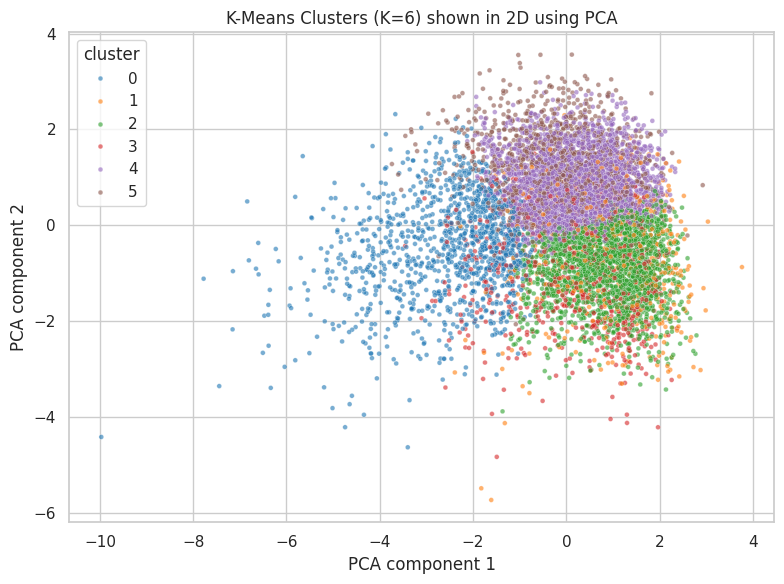

In [7]:
# Part 5b - Final K-Means model, cluster plot, save model
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

df = pd.read_csv("dataset/spotify_cleaned.csv")
FEATURES = ["danceability", "energy", "loudness", "speechiness", "acousticness",
            "instrumentalness", "liveness", "valence", "tempo"]

# K chosen from kmeans_find_k.py results (see explanation):
# among K = 4..10, K = 6 has the best silhouette score (0.1575) and the elbow curve starts to flatten after it.
K = 6

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[FEATURES])

kmeans = KMeans(n_clusters=K, n_init=10, random_state=42)
df["cluster"] = kmeans.fit_predict(X_scaled)
print("Songs per cluster:\n", df["cluster"].value_counts().sort_index())

# Save model and scaler (the scaler is needed to prepare new songs the same way)
joblib.dump(kmeans, "model/kmeans_model.pkl")
joblib.dump(scaler, "model/scaler.pkl")
print("\nSaved model/kmeans_model.pkl and model/scaler.pkl")

# Cluster visualization: squeeze 9 features into 2 dimensions with PCA (only for drawing)
pca = PCA(n_components=2, random_state=42)
points = pca.fit_transform(X_scaled)
print("\nVariance explained by the 2 plot axes:", (pca.explained_variance_ratio_.sum() * 100).round(1), "%")

plot_df = pd.DataFrame({"PC1": points[:, 0], "PC2": points[:, 1], "cluster": df["cluster"]}).sample(8000, random_state=42)
plt.figure(figsize=(8, 6))
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="cluster", palette="tab10", s=12, alpha=0.6)
plt.title("K-Means Clusters (K=6) shown in 2D using PCA")
plt.xlabel("PCA component 1"); plt.ylabel("PCA component 2")
plt.tight_layout(); plt.savefig("visualizations/cluster_visualization.png", dpi=150); plt.show()


## 7. Cluster analysis
**What:** add the cluster number to each song, average the features per cluster, and compare clusters with playlist genre and playlist name.

Highlights: cluster 3 (very high instrumentalness) is 56.3% EDM, and cluster 5 (very high speechiness) is 57.5% rap. Clusters 1, 2 and 4 mix several genres. Playlists with a specific style, for example *Hard Rock Workout*, fall mostly into one cluster (83.6% in cluster 2).

Songs per cluster:
 cluster
0    3743
1    1679
2    6736
3    2169
4    8366
5    3536
Name: count, dtype: int64

Average features per cluster:
          danceability  energy  loudness  speechiness  acousticness  instrumentalness  liveness  valence    tempo
cluster                                                                                                         
0               0.600   0.416   -10.691        0.072         0.541             0.108     0.146    0.386  112.532
1               0.606   0.785    -6.013        0.113         0.122             0.066     0.628    0.502  122.642
2               0.548   0.790    -5.338        0.073         0.069             0.024     0.175    0.373  132.687
3               0.667   0.775    -7.123        0.071         0.075             0.755     0.166    0.392  124.834
4               0.739   0.723    -6.376        0.076         0.146             0.017     0.149    0.682  113.943
5               0.725   0.663    -6.930        0.316         0.

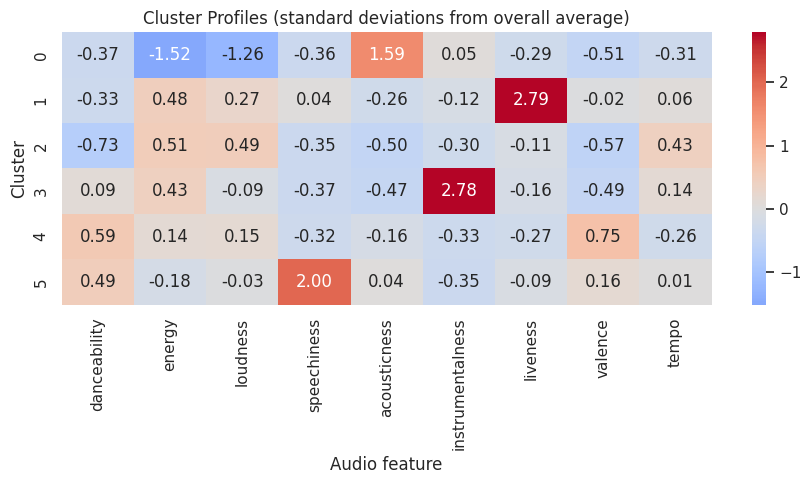


Cluster vs Genre (% of each cluster):
 playlist_genre   edm  latin   pop   r&b   rap  rock
cluster                                            
0                3.7   11.3  19.2  31.8  16.3  17.8
1               26.3   13.2  15.0  11.3  16.5  17.7
2               25.8    7.9  23.6   7.3  10.7  24.7
3               56.3    8.4  12.4   3.4  10.9   8.6
4               10.2   24.5  21.4  17.8  15.4  10.7
5                5.9   11.5   6.2  18.0  57.5   0.9

Overall genre share (%):
 {'rap': 19.7, 'pop': 18.4, 'edm': 17.5, 'r&b': 15.5, 'latin': 14.6, 'rock': 14.3}


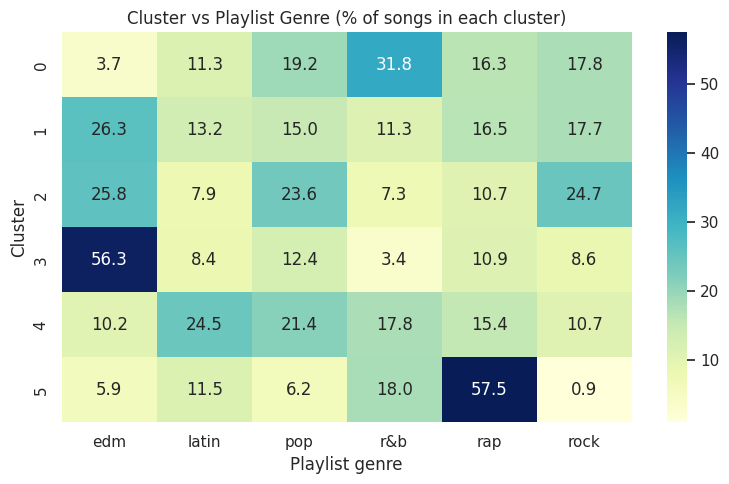


Cluster vs top-10 Playlist Names (% of each playlist's songs):
 cluster                0     1     2     3     4     5
playlist_name                                         
Indie Poptimism      5.7   5.3  42.4   2.8  41.3   2.5
Permanent Wave      17.3   6.2  48.6  11.1  16.3   0.5
Hard Rock Workout    0.0   7.5  83.6   3.0   4.5   1.5
Southern Hip Hop     1.2  10.4   9.1   0.0  26.2  53.0
Urban Contemporary  32.9  11.0  15.5   3.9  18.7  18.1
post teen pop        4.3   6.5  33.1   0.0  50.4   5.8
Dance Pop            2.2   5.2  48.1   2.2  38.5   3.7
Urban contemporary  72.8   0.0   9.6   3.5   7.0   7.0
Tropical Vibes       3.6   2.7  18.0  49.5  24.3   1.8
New Jack Swing      13.1   5.6   5.6   0.9  71.0   3.7


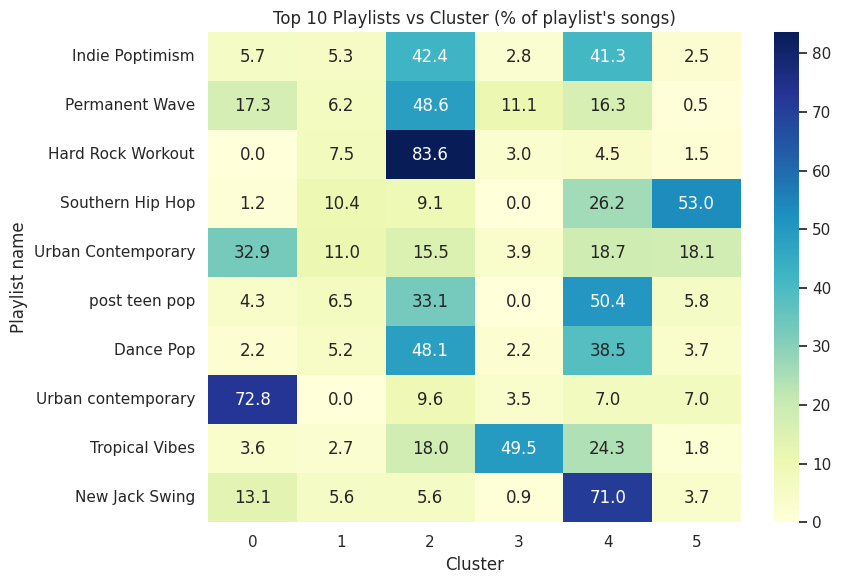


Most common playlist names inside each cluster:
0 {'Lush Lofi': 89, 'Urban contemporary': 83, 'Lo-Fi Beats': 65}
1 {'Unplugged Hits 📣': 37, 'Verão 2020 | Pop | Funk | Sertanejo | EDM | Top Hits 2019 - As Mais Tocadas': 29, 'Rock and Rios': 25}
2 {'Hard Rock Workout': 168, 'Indie Poptimism': 120, 'Permanent Wave': 101}
3 {'Underground Party | Hypnotic | Minimal | Acid | Big Room | Tech | Liquid': 88, 'House Electro 2019': 79, 'Selected House': 62}
4 {'Indie Poptimism': 117, 'Paraiso Tropical': 88, 'MIX LATIN POP°': 83}
5 {'Southern Hip Hop': 87, 'Gangster Rap Deutsch': 81, 'GANGSTA Rap': 70}


In [8]:
# Part 6 - Cluster Analysis
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 200)
df = pd.read_csv("dataset/spotify_cleaned.csv")
FEATURES = ["danceability", "energy", "loudness", "speechiness", "acousticness",
            "instrumentalness", "liveness", "valence", "tempo"]

# 1. Add cluster number to each song (using the saved scaler and model from Part 5)
scaler = joblib.load("model/scaler.pkl")
kmeans = joblib.load("model/kmeans_model.pkl")
df["cluster"] = kmeans.predict(scaler.transform(df[FEATURES]))
df.to_csv("dataset/spotify_clustered.csv", index=False)

# 2. Count songs in each cluster
print("Songs per cluster:\n", df["cluster"].value_counts().sort_index())

# 3. Average audio features per cluster (real units) + overall average for comparison
profile = df.groupby("cluster")[FEATURES].mean()
print("\nAverage features per cluster:\n", profile.round(3))
print("\nOverall average:\n", df[FEATURES].mean().round(3).to_dict())

# Same table as 'how many standard deviations above/below the overall average' (easier to compare)
z_profile = (profile - df[FEATURES].mean()) / df[FEATURES].std()
print("\nCluster profile in standard deviations (+ = above average, - = below):\n", z_profile.round(2))

plt.figure(figsize=(9, 5))
sns.heatmap(z_profile, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Cluster Profiles (standard deviations from overall average)")
plt.xlabel("Audio feature"); plt.ylabel("Cluster")
plt.tight_layout(); plt.savefig("visualizations/cluster_profiles.png", dpi=150); plt.show()

# 5. Cluster vs Playlist Genre (each row = one cluster, values = % of that cluster's songs)
genre_pct = pd.crosstab(df["cluster"], df["playlist_genre"], normalize="index") * 100
print("\nCluster vs Genre (% of each cluster):\n", genre_pct.round(1))
print("\nOverall genre share (%):\n", (df["playlist_genre"].value_counts(normalize=True) * 100).round(1).to_dict())

plt.figure(figsize=(8, 5))
sns.heatmap(genre_pct, annot=True, fmt=".1f", cmap="YlGnBu")
plt.title("Cluster vs Playlist Genre (% of songs in each cluster)")
plt.xlabel("Playlist genre"); plt.ylabel("Cluster")
plt.tight_layout(); plt.savefig("visualizations/cluster_vs_genre.png", dpi=150); plt.show()

# 6. Cluster vs Playlist Name (449 names, so we use the 10 playlists with the most songs)
top_names = df["playlist_name"].value_counts().head(10).index
name_pct = pd.crosstab(df[df["playlist_name"].isin(top_names)]["playlist_name"],
                       df[df["playlist_name"].isin(top_names)]["cluster"], normalize="index") * 100
name_pct = name_pct.loc[top_names]
print("\nCluster vs top-10 Playlist Names (% of each playlist's songs):\n", name_pct.round(1))

plt.figure(figsize=(9, 6))
sns.heatmap(name_pct, annot=True, fmt=".1f", cmap="YlGnBu")
plt.title("Top 10 Playlists vs Cluster (% of playlist's songs)")
plt.xlabel("Cluster"); plt.ylabel("Playlist name")
plt.tight_layout(); plt.savefig("visualizations/cluster_vs_playlist_name.png", dpi=150); plt.show()

# Extra: top 3 playlist names inside each cluster
print("\nMost common playlist names inside each cluster:")
for c in sorted(df["cluster"].unique()):
    print(c, df[df["cluster"] == c]["playlist_name"].value_counts().head(3).to_dict())


## 8. Recommendation system
**What:** content-based recommender using cosine similarity on the scaled audio features. The code is in `backend/recommender.py`, and Flask uses the same file.
**How:** find the selected song, compute its cosine similarity with every song, and return the top 5.

In [9]:
from recommender import df as songs_df, recommend_song

song = songs_df[songs_df["playlist_genre"] == "rap"].sort_values("track_popularity", ascending=False).iloc[0]
print("Selected:", song["track_name"], "-", song["track_artist"], "| genre:", song["playlist_genre"])
recommend_song(song["track_name"], n=5)


Selected: The Box - Roddy Ricch | genre: rap


,Song Name,Artist,Genre,Similarity Score
0,Tengo Tantas Ganas de Ti,Arcangel,latin,0.9838
1,Rather Be,Clean Bandit,pop,0.9807
2,Grow Up,Bolier,latin,0.9793
3,Buoy,RICCI,edm,0.9654
4,Get Your Way,Brasstracks,r&b,0.9607


In [10]:
# Invalid song name is handled with a clear message
try:
    recommend_song("zzzz not a song")
except ValueError as error:
    print(error)


Song 'zzzz not a song' was not found in the dataset. Please try another name.


### Quick evaluation
How often do the 5 recommended songs have the same genre as the selected song, compared with picking songs at random? (Measured on 300 random songs.) Earlier run: **36.7%** vs a random baseline of **16.9%**.

In [11]:
from recommender import df, recommend_song, search_songs, find_song
# Part 7 - Test and evaluate the recommender
import pandas as pd

pd.set_option("display.width", 200)

# 1. Show recommendations for the most popular song of 3 different genres (taken from the data, not typed by hand)
for genre in ["rock", "rap", "latin"]:
    song = df[df["playlist_genre"] == genre].sort_values("track_popularity", ascending=False).iloc[0]
    print(f"\n=== Selected: {song['track_name']} - {song['track_artist']} (genre: {genre}) ===")
    print(recommend_song(song["track_name"], n=5).to_string())

# 2. Upper/lower case and partial names still work, invalid names give a clear message
song_name = df.iloc[0]["track_name"]
found = df.loc[find_song(song_name.upper()), "track_name"]
print(f"\nTyped '{song_name.upper()}' -> matched song: '{found}'")
print("search_songs('love') ->", search_songs("love", limit=3))
try:
    recommend_song("zzzz not a song")
except ValueError as e:
    print("Invalid name ->", e)

# 3. Simple check: do recommended songs share the genre of the selected song?
test_songs = df.sample(300, random_state=42)
same_genre = 0
total = 0
for idx, row in test_songs.iterrows():
    recs = recommend_song(row["track_name"], n=5)
    same_genre += (recs["Genre"] == row["playlist_genre"]).sum()
    total += len(recs)
print(f"\nGenre check on 300 random songs: {same_genre / total * 100:.1f}% of recommended songs have the same genre as the selected song")

# Baseline: chance of matching genre if we picked songs completely at random
share = df["playlist_genre"].value_counts(normalize=True)
print(f"Random-pick baseline: {(share ** 2).sum() * 100:.1f}%")



=== Selected: Bohemian Rhapsody - 2011 Mix - Queen (genre: rock) ===
                             Song Name          Artist  Genre  Similarity Score
0  Bohemian Rhapsody - Remastered 2011           Queen   rock            1.0000
1                                Hello      Blackfield   rock            0.9723
2                     I See Your Smile  Gloria Estefan  latin            0.9659
3                                Quiet   Natalie Weiss    r&b            0.9641
4                       Una y Otra Vez  Manuel Medrano  latin            0.9588

=== Selected: The Box - Roddy Ricch (genre: rap) ===
                  Song Name        Artist  Genre  Similarity Score
0  Tengo Tantas Ganas de Ti      Arcangel  latin            0.9838
1                 Rather Be  Clean Bandit    pop            0.9807
2                   Grow Up        Bolier  latin            0.9793
3                      Buoy         RICCI    edm            0.9654
4              Get Your Way   Brasstracks    r&b            0


Genre check on 300 random songs: 36.7% of recommended songs have the same genre as the selected song
Random-pick baseline: 16.9%


## 9. Conclusion
- The dataset was cleaned to 26,229 unique songs.
- Audio features differ between genres, but only partly: some clusters match a genre well and others mix genres.
- The recommender returns songs with a similar sound and does better than random on genre agreement.
- The Flask app (`python backend/app.py`) connects the recommender to the web page.